# 06 Fingerprint Generation

This notebook generates **behavioural fingerprint vectors** for BotPrint from session-level features.

**Input:** `dataset/processed/session_features.csv` (from `05_feature_extraction.ipynb`). Raw data in `dataset/raw/` is not modified.

**Important constraints:**
- `SessionID`, `BotID`, `CoordinationGroupID`, `UserType`, and `BotType` are **never** included in fingerprint vectors.
- `SessionID` is preserved separately for identification; `UserType` and `BotType` are preserved separately for evaluation only.
- Fingerprints are **behavioural representations for this research**. We do **not** claim they uniquely identify users.
- Scaling/imputation parameters in this exploratory dataset are estimated from the **available sessions**. For future model experiments, fit preprocessing/scaling **only on training data** and apply to evaluation data to avoid leakage.

**Outputs (saved):**
- `dataset/processed/fingerprint_raw_matrix.csv`
- `dataset/processed/fingerprint_imputed_matrix.csv`
- `dataset/processed/fingerprint_processed_matrix.csv`
- `dataset/processed/fingerprint_dataset.csv`
- `dataset/processed/fingerprint_config.json`
- `dataset/processed/fingerprint_scaler.joblib`
- `reports/analysis/fingerprint_scaler_comparison.csv`
- `reports/analysis/fingerprint_feature_missingness.csv`
- `reports/analysis/fingerprint_summary.csv`

In [1]:
# 1. Setup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import sys
import json
import warnings

warnings.filterwarnings('ignore', category=FutureWarning)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 120

# Resolve project root
_here = Path.cwd()
_root = _here
for _ in range(5):
    if (_root / 'README.md').exists() and (_root / 'dataset').exists():
        break
    _root = _root.parent
PROJECT_ROOT = _root
if str(PROJECT_ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / 'src'))

from fingerprint import (
    generate_fingerprints,
    save_fingerprint_artifacts,
    select_fingerprint_features,
    EXCLUDED_FROM_FINGERPRINT,
)

DATA_PATH = PROJECT_ROOT / 'dataset' / 'processed' / 'session_features.csv'
PROCESSED_DIR = PROJECT_ROOT / 'dataset' / 'processed'
ANALYSIS_DIR = PROJECT_ROOT / 'reports' / 'analysis'
FIG_DIR = PROJECT_ROOT / 'reports' / 'figures'
for d in [PROCESSED_DIR, ANALYSIS_DIR, FIG_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print('Project root:', PROJECT_ROOT)
print('Input exists:', DATA_PATH.exists())


Project root: C:\My KS\Research\BotPrint-Research
Input exists: True


In [2]:
# 2. Load session-level feature dataset
df = pd.read_csv(DATA_PATH)
print('Shape:', df.shape)
print('Sessions:', df['SessionID'].nunique())
print('Columns:', list(df.columns))
df.head()


Shape: (24, 38)
Sessions: 24
Columns: ['SessionID', 'UserType', 'BotType', 'CoordinationGroupID', 'SessionSource', 'BotID', 'session_duration_s', 'session_total_events', 'session_event_frequency', 'session_mean_idle_ms', 'session_navigation_count', 'mouse_event_count', 'mouse_has_data', 'mouse_mean_speed', 'mouse_std_speed', 'mouse_mean_acceleration', 'mouse_std_acceleration', 'mouse_total_distance', 'mouse_movement_frequency', 'mouse_direction_changes', 'keyboard_event_count', 'keyboard_has_data', 'keyboard_mean_interkey_ms', 'keyboard_std_interkey_ms', 'keyboard_typing_frequency', 'keyboard_typing_count', 'click_event_count', 'click_has_data', 'click_mean_interval_ms', 'click_std_interval_ms', 'click_frequency', 'click_count', 'scroll_event_count', 'scroll_has_data', 'scroll_mean_speed', 'scroll_std_speed', 'scroll_mean_delta', 'scroll_count']


,SessionID,UserType,BotType,CoordinationGroupID,SessionSource,BotID,session_duration_s,session_total_events,session_event_frequency,session_mean_idle_ms,...,click_mean_interval_ms,click_std_interval_ms,click_frequency,click_count,scroll_event_count,scroll_has_data,scroll_mean_speed,scroll_std_speed,scroll_mean_delta,scroll_count
0,S-0108f7d0-0f85-4c15-a643-b0d53c0da2d8,Human,NaN,NaN,Manual,NaN,38.104,118,3.096788,309.779661,...,4473.571429,5074.442001,0.209952,8.0,1,1,66.399994,0.000000,66.399994,1.0
1,S-1710524c-4560-4abd-906c-6f336edff5de,Bot,CoordinatedBot,coord-f8d0256724,Selenium,bot-02-f02697,31.078,56,1.801918,510.696429,...,2320.166667,2957.473206,0.321771,10.0,2,1,49.002278,69.293242,119.000000,2.0
2,S-1f44b887-5413-4283-91dc-5ac39b63feff,Bot,RandomBot,coord-33f0cbe678,Selenium,bot-02-3d3eda,18.660,12,0.643087,168.333333,...,NaN,NaN,0.053591,1.0,1,1,0.104732,0.000000,66.400024,1.0
3,S-2510ce7a-5d0f-479d-89e2-a251a2e9a162,Bot,RandomBot,coord-33f0cbe678,Selenium,bot-03-142623,20.055,22,1.096983,215.318182,...,1109.500000,263.750829,0.199452,4.0,0,0,NaN,NaN,NaN,0.0
4,S-28ae68f8-c6e5-44f9-8120-1385f632233c,Bot,RandomBot,coord-33f0cbe678,Selenium,bot-04-8cc701,18.770,18,0.958977,214.777778,...,NaN,NaN,0.053277,1.0,1,1,0.143723,0.000000,66.400024,1.0


## 3. Exclude identifiers and target labels

The fingerprint vector must contain only behavioural measurements/derived behavioural features. The following are excluded from the vector:

- Identifiers: `SessionID`, `BotID`
- Coordination/labels: `CoordinationGroupID`, `UserType`, `BotType`
- Optional metadata: `SessionSource` (if present)

`SessionID` is preserved separately for identification; `UserType` and `BotType` are preserved separately for evaluation.

In [3]:
# 3. Verify exclusions
excluded = [c for c in df.columns if c in EXCLUDED_FROM_FINGERPRINT]
print('Columns excluded from fingerprint vectors:', excluded)
print('Remaining columns:', [c for c in df.columns if c not in EXCLUDED_FROM_FINGERPRINT])


Columns excluded from fingerprint vectors: ['SessionID', 'UserType', 'BotType', 'CoordinationGroupID', 'SessionSource', 'BotID']
Remaining columns: ['session_duration_s', 'session_total_events', 'session_event_frequency', 'session_mean_idle_ms', 'session_navigation_count', 'mouse_event_count', 'mouse_has_data', 'mouse_mean_speed', 'mouse_std_speed', 'mouse_mean_acceleration', 'mouse_std_acceleration', 'mouse_total_distance', 'mouse_movement_frequency', 'mouse_direction_changes', 'keyboard_event_count', 'keyboard_has_data', 'keyboard_mean_interkey_ms', 'keyboard_std_interkey_ms', 'keyboard_typing_frequency', 'keyboard_typing_count', 'click_event_count', 'click_has_data', 'click_mean_interval_ms', 'click_std_interval_ms', 'click_frequency', 'click_count', 'scroll_event_count', 'scroll_has_data', 'scroll_mean_speed', 'scroll_std_speed', 'scroll_mean_delta', 'scroll_count']


## 4. Investigate feature missingness

Session-level features can be missing when a session lacks sufficient events of a given type or valid measurements. We report missingness and select features with adequate coverage, while keeping the missing-value policy explicit.

In [4]:
# 4. Missingness investigation
feature_cols, indicator_cols, selection_report = select_fingerprint_features(
    df, min_non_missing_ratio=0.25, include_indicators=False
)
miss_rows = []
for feat, info in selection_report['missingness'].items():
    miss_rows.append({'feature': feat, **info})
miss = pd.DataFrame(miss_rows).sort_values(['non_missing_ratio','feature'], ascending=[True, True])
print('Selected behavioural features:', len(feature_cols))
print('Dropped (low coverage):', selection_report['dropped_low_coverage'])
print('Indicator columns available (not in vector by default):', indicator_cols)
miss


Selected behavioural features: 24
Dropped (low coverage): []
Indicator columns available (not in vector by default): ['mouse_event_count', 'mouse_has_data', 'keyboard_event_count', 'keyboard_has_data', 'click_event_count', 'click_has_data', 'scroll_event_count', 'scroll_has_data']


,feature,non_missing_ratio,n_missing,n_non_missing
16,click_mean_interval_ms,0.5833,10,14
17,click_std_interval_ms,0.5833,10,14
22,scroll_mean_delta,0.5833,10,14
20,scroll_mean_speed,0.5833,10,14
21,scroll_std_speed,0.5833,10,14
11,mouse_direction_changes,0.6250,9,15
18,click_frequency,0.7500,6,18
7,mouse_mean_acceleration,0.7500,6,18
5,mouse_mean_speed,0.7500,6,18
10,mouse_movement_frequency,0.7500,6,18


## 5. Meaningful behavioural feature selection

Selected features are numeric behavioural aggregates/rates/variability measures derived from mouse, keyboard, click, scroll, and session behaviour. Availability indicators (`*_has_data`, `*_event_count`) are retained in the source dataset for interpretation but are not included in the default fingerprint magnitude vector.

In [5]:
# 5. Selected features
print('Fingerprint feature list ({}):'.format(len(feature_cols)))
for c in feature_cols:
    print(' -', c)


Fingerprint feature list (24):
 - session_duration_s
 - session_total_events
 - session_event_frequency
 - session_mean_idle_ms
 - session_navigation_count
 - mouse_mean_speed
 - mouse_std_speed
 - mouse_mean_acceleration
 - mouse_std_acceleration
 - mouse_total_distance
 - mouse_movement_frequency
 - mouse_direction_changes
 - keyboard_mean_interkey_ms
 - keyboard_std_interkey_ms
 - keyboard_typing_frequency
 - keyboard_typing_count
 - click_mean_interval_ms
 - click_std_interval_ms
 - click_frequency
 - click_count
 - scroll_mean_speed
 - scroll_std_speed
 - scroll_mean_delta
 - scroll_count


## 6-7. Missing-value handling and scaler comparison

- **Missing values:** imputed using the **median** per feature (robust to skew/outliers). Imputation is fit on the available sessions for this exploratory dataset.
- **Scaling:** we compare `StandardScaler` (mean/std) and `RobustScaler` (median/IQR).
- **Selection rationale:** behavioural telemetry can contain outliers (e.g., unusually long sessions or extreme speeds). `RobustScaler` is less sensitive to outliers than `StandardScaler`, so it is the default exploratory choice when appropriate; the comparison table is saved for transparency.

**Leakage note:** scaling/imputation parameters are estimated from all available sessions here. For future supervised model experiments, **fit imputer/scaler only on training data** and transform evaluation data.

In [6]:
# 6-8. Generate fingerprints (includes imputation + scaler comparison)
artifacts = generate_fingerprints(df, min_non_missing_ratio=0.25)
print('Selected scaler:', artifacts['config'].selected_scaler)
print('Imputation:', artifacts['config'].imputation_strategy)
print('Scaling fit note:', artifacts['config'].scaling_fit_note)
artifacts['comparison']


Selected scaler:

 RobustScaler
Imputation: median
Scaling fit note: Scaling/imputation parameters estimated from all available sessions in this exploratory fingerprint dataset. For future supervised evaluation, fit preprocessing ONLY on training data and apply to evaluation data to avoid leakage.


,scaler,mean_of_means,mean_of_stds,median_of_medians,max_abs_value,note
0,StandardScaler,1.252856e-17,1.021508,-0.352453,4.697573,Fit on all available sessions (exploratory; do...
1,RobustScaler,3.193520e+00,14.246589,0.000000,522.685809,Fit on all available sessions (exploratory; do...


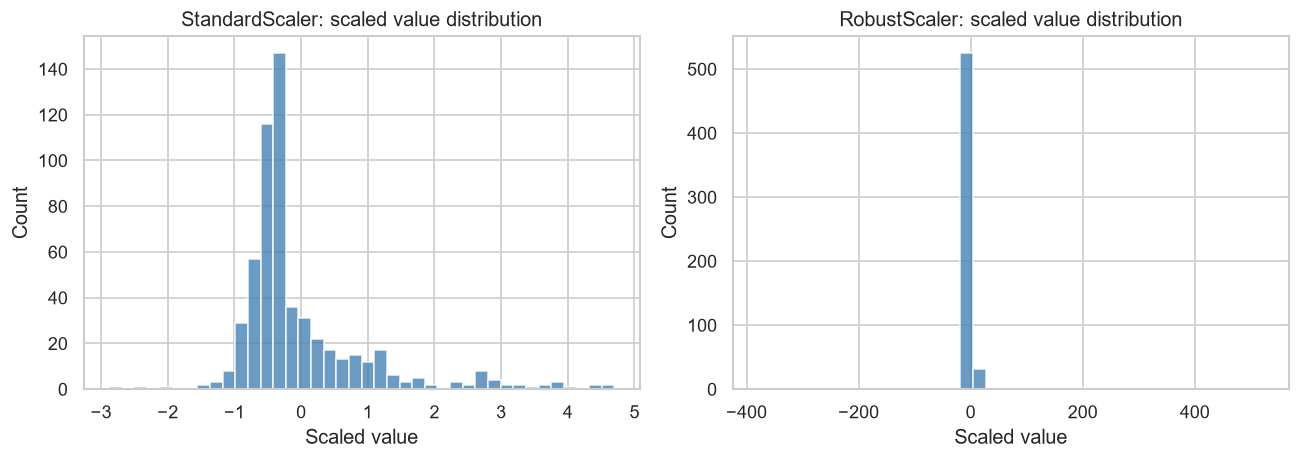

In [7]:
# Visual comparison: distribution of scaled feature means/stds
proc_std = None
proc_rob = None
# Recompute both for visual comparison (using same imputed base)
from sklearn.preprocessing import StandardScaler, RobustScaler
imp = artifacts['imputed_matrix']
std_m = pd.DataFrame(StandardScaler().fit_transform(imp), columns=imp.columns)
rob_m = pd.DataFrame(RobustScaler().fit_transform(imp), columns=imp.columns)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, mat, name in [(axes[0], std_m, 'StandardScaler'), (axes[1], rob_m, 'RobustScaler')]:
    ax.hist(mat.values.flatten(), bins=40, alpha=0.8, color='steelblue')
    ax.set_title(f'{name}: scaled value distribution')
    ax.set_xlabel('Scaled value')
    ax.set_ylabel('Count')
plt.tight_layout()
plt.savefig(FIG_DIR / 'fingerprint_scaler_comparison.png', bbox_inches='tight')
plt.show()


## 9. Numerical fingerprint vectors

Each session is represented by a fixed-length numerical vector over the selected behavioural features (after median imputation and selected scaling).

In [8]:
# 9. Fingerprint vectors
raw = artifacts['raw_matrix']
processed = artifacts['processed_matrix']
print('Raw feature matrix shape:', raw.shape)
print('Processed fingerprint matrix shape:', processed.shape)
print('Fingerprint columns:', list(processed.columns))
processed.head()


Raw feature matrix shape: (24, 24)
Processed fingerprint matrix shape: (24, 24)
Fingerprint columns: ['session_duration_s', 'session_total_events', 'session_event_frequency', 'session_mean_idle_ms', 'session_navigation_count', 'mouse_mean_speed', 'mouse_std_speed', 'mouse_mean_acceleration', 'mouse_std_acceleration', 'mouse_total_distance', 'mouse_movement_frequency', 'mouse_direction_changes', 'keyboard_mean_interkey_ms', 'keyboard_std_interkey_ms', 'keyboard_typing_frequency', 'keyboard_typing_count', 'click_mean_interval_ms', 'click_std_interval_ms', 'click_frequency', 'click_count', 'scroll_mean_speed', 'scroll_std_speed', 'scroll_mean_delta', 'scroll_count']


,session_duration_s,session_total_events,session_event_frequency,session_mean_idle_ms,session_navigation_count,mouse_mean_speed,mouse_std_speed,mouse_mean_acceleration,mouse_std_acceleration,mouse_total_distance,...,keyboard_typing_frequency,keyboard_typing_count,click_mean_interval_ms,click_std_interval_ms,click_frequency,click_count,scroll_mean_speed,scroll_std_speed,scroll_mean_delta,scroll_count
0,0.906991,1.708155,0.559981,0.827274,1.0,1.167621,2.444249,11.676459,10.288716,2.510886,...,0.771526,1.174603,13.595014,13.118154,-0.006884,0.769231,1.586700,-1.048817,-0.000076,0.0
1,0.579717,0.643777,0.000000,2.050604,0.0,-0.183014,-0.033261,-0.088824,-0.050602,-0.561015,...,0.698063,0.857143,2.033110,5.606179,0.929718,1.076923,1.051197,232.444900,262.953812,0.5
2,0.001281,-0.111588,-0.501149,-0.033956,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,...,-0.879259,-0.095238,0.000000,0.000000,-1.316570,-0.307692,-0.453872,-1.048817,0.000076,0.0
3,0.066261,0.060086,-0.304857,0.252122,0.0,-0.170918,0.033261,0.029923,-0.023370,-0.561688,...,-0.740391,-0.031746,-4.467114,-3.952381,-0.094834,0.153846,0.000000,0.000000,0.000000,-0.5
4,0.006405,-0.008584,-0.364539,0.248832,0.0,0.070201,0.316874,0.244315,0.023370,-0.627685,...,-0.355071,0.063492,0.000000,0.000000,-1.319201,-0.307692,-0.452672,-1.048817,0.000076,0.0


## 10-11. Preserve identifiers and labels separately

The fingerprint dataset stores `SessionID` (identification) and `UserType`/`BotType` (evaluation labels) alongside the fingerprint vector. These columns are metadata/labels and are **not** part of the fingerprint dimensions.

In [9]:
# 10-11. Fingerprint dataset (id + labels + vector)
fp = artifacts['fingerprint_df']
id_label_cols = [c for c in fp.columns if c in EXCLUDED_FROM_FINGERPRINT]
vector_cols = [c for c in fp.columns if c not in EXCLUDED_FROM_FINGERPRINT]
print('ID/label columns (separate):', id_label_cols)
print('Fingerprint vector dimensions:', len(vector_cols))
assert 'SessionID' not in vector_cols, 'SessionID leaked into vector'
assert 'UserType' not in vector_cols, 'UserType leaked into vector'
assert 'BotType' not in vector_cols, 'BotType leaked into vector'
assert 'CoordinationGroupID' not in vector_cols, 'CoordinationGroupID leaked into vector'
assert 'BotID' not in vector_cols, 'BotID leaked into vector'
print('Leakage checks passed.')
fp.head()


ID/label columns (separate): ['SessionID', 'UserType', 'BotType', 'CoordinationGroupID', 'SessionSource', 'BotID']
Fingerprint vector dimensions: 24
Leakage checks passed.


,SessionID,UserType,BotType,CoordinationGroupID,SessionSource,BotID,session_duration_s,session_total_events,session_event_frequency,session_mean_idle_ms,...,keyboard_typing_frequency,keyboard_typing_count,click_mean_interval_ms,click_std_interval_ms,click_frequency,click_count,scroll_mean_speed,scroll_std_speed,scroll_mean_delta,scroll_count
0,S-0108f7d0-0f85-4c15-a643-b0d53c0da2d8,Human,NaN,NaN,Manual,NaN,0.906991,1.708155,0.559981,0.827274,...,0.771526,1.174603,13.595014,13.118154,-0.006884,0.769231,1.586700,-1.048817,-0.000076,0.0
1,S-1710524c-4560-4abd-906c-6f336edff5de,Bot,CoordinatedBot,coord-f8d0256724,Selenium,bot-02-f02697,0.579717,0.643777,0.000000,2.050604,...,0.698063,0.857143,2.033110,5.606179,0.929718,1.076923,1.051197,232.444900,262.953812,0.5
2,S-1f44b887-5413-4283-91dc-5ac39b63feff,Bot,RandomBot,coord-33f0cbe678,Selenium,bot-02-3d3eda,0.001281,-0.111588,-0.501149,-0.033956,...,-0.879259,-0.095238,0.000000,0.000000,-1.316570,-0.307692,-0.453872,-1.048817,0.000076,0.0
3,S-2510ce7a-5d0f-479d-89e2-a251a2e9a162,Bot,RandomBot,coord-33f0cbe678,Selenium,bot-03-142623,0.066261,0.060086,-0.304857,0.252122,...,-0.740391,-0.031746,-4.467114,-3.952381,-0.094834,0.153846,0.000000,0.000000,0.000000,-0.5
4,S-28ae68f8-c6e5-44f9-8120-1385f632233c,Bot,RandomBot,coord-33f0cbe678,Selenium,bot-04-8cc701,0.006405,-0.008584,-0.364539,0.248832,...,-0.355071,0.063492,0.000000,0.000000,-1.319201,-0.307692,-0.452672,-1.048817,0.000076,0.0


## 12. Save scaler and feature configuration

The fitted imputer/scaler and configuration are saved for reproducibility. The configuration records that scaling parameters were estimated from available sessions in this exploratory dataset.

In [10]:
# 12-13. Save all outputs
save_fingerprint_artifacts(artifacts, PROCESSED_DIR, ANALYSIS_DIR)

config_path = PROCESSED_DIR / 'fingerprint_config.json'
scaler_path = PROCESSED_DIR / 'fingerprint_scaler.joblib'
print('Saved config:', config_path)
print('Saved scaler/imputer:', scaler_path)
print(json.dumps(json.loads(config_path.read_text(encoding='utf-8')), indent=2))


Saved config: C:\My KS\Research\BotPrint-Research\dataset\processed\fingerprint_config.json
Saved scaler/imputer: C:\My KS\Research\BotPrint-Research\dataset\processed\fingerprint_scaler.joblib
{
  "feature_columns": [
    "session_duration_s",
    "session_total_events",
    "session_event_frequency",
    "session_mean_idle_ms",
    "session_navigation_count",
    "mouse_mean_speed",
    "mouse_std_speed",
    "mouse_mean_acceleration",
    "mouse_std_acceleration",
    "mouse_total_distance",
    "mouse_movement_frequency",
    "mouse_direction_changes",
    "keyboard_mean_interkey_ms",
    "keyboard_std_interkey_ms",
    "keyboard_typing_frequency",
    "keyboard_typing_count",
    "click_mean_interval_ms",
    "click_std_interval_ms",
    "click_frequency",
    "click_count",
    "scroll_mean_speed",
    "scroll_std_speed",
    "scroll_mean_delta",
    "scroll_count"
  ],
  "indicator_columns": [
    "mouse_event_count",
    "mouse_has_data",
    "keyboard_event_count",
    "keyboa

## 14. Fingerprint summary

In [11]:
# 14. Summary
summary = artifacts['summary']
summary.to_csv(ANALYSIS_DIR / 'fingerprint_summary.csv', index=False)
print(summary.to_string(index=False))

# Simple descriptive profile (not a uniqueness claim)
print('\nPer-session fingerprint L2 norm (descriptive):')
norms = np.linalg.norm(processed.values, axis=1)
norm_df = pd.DataFrame({'SessionID': fp['SessionID'], 'UserType': fp.get('UserType'), 'fingerprint_l2_norm': norms})
print(norm_df.to_string(index=False))
norm_df.to_csv(ANALYSIS_DIR / 'fingerprint_norms.csv', index=False)


                    metric                                                                     value
                n_sessions                                                                        24
    n_fingerprint_features                                                                        24
           selected_scaler                                                              RobustScaler
       imputation_strategy                                                                    median
  n_excluded_id_label_cols                                                                         6
n_indicator_cols_available                                                                         8
         fingerprint_claim Behavioural representations for research; not unique user identification.

Per-session fingerprint L2 norm (descriptive):
                             SessionID UserType  fingerprint_l2_norm
S-0108f7d0-0f85-4c15-a643-b0d53c0da2d8    Human            29.738889
S-1710

## 15. Conclusion

This notebook produced exploratory session-level behavioural fingerprint vectors from selected session features. It excluded all identifiers/target labels from the vector, preserved `SessionID`/`UserType`/`BotType` separately, investigated missingness, applied median imputation and a documented scaling choice (with `StandardScaler` vs `RobustScaler` comparison), and saved matrices, dataset, config, and fitted artifacts. Fingerprints are behavioural representations for BotPrint research and are **not** claimed to uniquely identify users.